# Multi-modal RAG System

Many documents contain a mixture of content types, including text, tables and images.

Yet, information captured in images is lost in most RAG applications.

With the emergence of multimodal LLMs, like [GPT-4o-mini](https://openai.com/index/hello-gpt-4o/), it is worth considering how to utilize images in RAG Systems:

![](https://i.imgur.com/wcCDT38.gif)


---

* Use a multimodal LLM (such as [GPT-4o-mini](https://openai.com/index/hello-gpt-4o/), [LLaVA](https://llava.hliu.cc/), or [FUYU-8b](https://www.adept.ai/blog/fuyu-8b)) to produce text summaries from images and tables
* Embed and retrieve image, table and text summaries with a reference to the raw images and tables for given queries
* Pass raw images, tables and text chunks to a multimodal LLM for answer synthesis   

---



* We will use [Unstructured](https://unstructured.io/) to parse images, text, and tables from documents (PDFs).
* We will use the [multi-vector retriever](https://python.langchain.com/docs/modules/data_connection/retrievers/multi_vector) with [Chroma](https://www.trychroma.com/) and Redis to store raw text and images along with their summaries for retrieval.
* We will use GPT-4o-mini for both image summarization (for retrieval) as well as final answer synthesis from join review of images and texts (or tables).


___Created By: [Dipanjan (DJ)](https://www.linkedin.com/in/dipanjans/)___



## Install Dependencies

In [1]:
!pip install langchain==1.2.12
!pip install langchain-openai==1.1.11
!pip install langchain-community==0.4.1
!pip install langchain-chroma
!pip install redis==7.3.0

In [2]:
# to prevent 403 errors with unstructured.io till they fix it
# refer: https://github.com/Unstructured-IO/unstructured/issues/3795
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


True

In [3]:
# installed newer version of unstructured as older one has 403 errors
# still being investigated even if they pushed a fix
# refer: https://github.com/Unstructured-IO/unstructured/issues/3795 for more details
# this version is stable and should be good
! pip install "unstructured[pdf]==0.21.5"

In [4]:
# install OCR dependencies for unstructured
!sudo apt-get install tesseract-ocr
!sudo apt-get install poppler-utils

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (4.1.1-2.1build1).
0 upgraded, 0 newly installed, 0 to remove and 5 not upgraded.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
poppler-utils is already the newest version (22.02.0-2ubuntu0.12).
0 upgraded, 0 newly installed, 0 to remove and 5 not upgraded.


In [5]:
!pip install htmltabletomd==1.0.0

  Using cached htmltabletomd-1.0.0.tar.gz (3.8 kB)
  Preparing metadata (setup.py) ... done
  Using cached html2markdown-0.1.7.tar.gz (5.3 kB)
  Preparing metadata (setup.py) ... done
  Created wheel for htmltabletomd: filename=htmltabletomd-1.0.0-py2.py3-none-any.whl size=3579 sha256=ce9f93b6993429de7edf27b2b89b6a7285b1b3338feab8885ed6d013d795bc3f
  Stored in directory: /root/.cache/pip/wheels/3a/43/12/cd68815191ac1155b7be7c08d8299fe94fc6410bbea4870210
  Created wheel for html2markdown: filename=html2markdown-0.1.7-py3-none-any.whl size=5233 sha256=42c93b17482b90bb23d75a77d577ed2e4bf4b98361fba86411560b9ad6f34910
  Stored in directory: /root/.cache/pip/wheels/a8/07/3d/d2e5d872cc76dc1662efbf51aaf0cbf5a860c9b3232f27f985
Successfully built htmltabletomd html2markdown


## Data Loading & Processing

### Partition PDF tables, text, and images
  

In [67]:
!wget https://sgp.fas.org/crs/misc/IF10244.pdf

--2026-03-20 06:39:05--  https://sgp.fas.org/crs/misc/IF10244.pdf
Resolving sgp.fas.org (sgp.fas.org)... 172.67.186.125, 104.21.19.144, 2606:4700:3037::6815:1390, ...
Connecting to sgp.fas.org (sgp.fas.org)|172.67.186.125|:443... connected.
HTTP request sent, awaiting response... 202 Accepted
Length: unspecified [text/html]
Saving to: ‘IF10244.pdf.1’

IF10244.pdf.1           [ <=>                ]       0  --.-KB/s    in 0s      

2026-03-20 06:39:06 (0.00 B/s) - ‘IF10244.pdf.1’ saved [0]



In [6]:
!rm -rf ./figures

We run the loader function twice to first extract all tables and then load all text and chunk it.

Reason for this is in the latest version of unstructured, you lose the table elements if you chunk directly.
Refer to: https://github.com/Unstructured-IO/unstructured/issues/3827 for more details

So till they push a fix, we will use this method. Once fixed we will update the following loader section.

In [8]:
doc="/content/IF10244.pdf"

In [9]:
from langchain_community.document_loaders import UnstructuredPDFLoader

loader = UnstructuredPDFLoader(
    file_path=doc,
    strategy='hi_res',
    extract_images_in_pdf=True,
    infer_table_structure=True,
    mode='elements',
    image_output_dir_path='./figures'
)
data = loader.load()

yolox_l0.05.onnx:   0%|          | 0.00/217M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/274 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/115M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/46.8M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

In [10]:
[doc.metadata['category'] for doc in data if doc.metadata['category'] == 'Table']

['Table', 'Table']

In [11]:
tables = [doc for doc in data if doc.metadata['category'] == 'Table']

In [12]:
# Chunk text and extract text content
loader = UnstructuredPDFLoader(file_path=doc,
                               strategy='hi_res',
                               extract_images_in_pdf=True,
                               infer_table_structure=True,
                               chunking_strategy="by_title", # section-based chunking
                               max_characters=4000, # max size of chunks
                               new_after_n_chars=4000, # preferred size of chunks
                               combine_text_under_n_chars=2000, # smaller chunks < 2000 chars will be combined into a larger chunk
                               mode='elements',
                               image_output_dir_path='./figures')
texts = loader.load()

In [13]:
len(texts)

5

In [14]:
data = texts + tables

In [15]:
len(data)

7

In [16]:
data[5]

Document(metadata={'source': '/content/IF10244.pdf', 'detection_class_prob': 0.9178253412246704, 'is_extracted': 'partial', 'coordinates': {'points': ((np.float64(290.2346496582031), np.float64(2225.298583984375)), (np.float64(290.2346496582031), np.float64(3444.36279296875)), (np.float64(1435.4814453125), np.float64(3444.36279296875)), (np.float64(1435.4814453125), np.float64(2225.298583984375))), 'system': 'PixelSpace', 'layout_width': 2975, 'layout_height': 3850}, 'last_modified': '2026-03-20T09:32:08', 'text_as_html': '<table><thead><tr><th></th><th>2018</th><th>2019</th><th>2020</th><th>2021</th><th>2022</th></tr></thead><tbody><tr><td colspan="6">Number of Fires (thousands)</td></tr><tr><td>Federal</td><td>12.5</td><td>10.9</td><td>14.4</td><td>14.0</td><td>11.7</td></tr><tr><td>FS</td><td>5.6</td><td>5.3</td><td>6.7</td><td>6.2</td><td>5.9</td></tr><tr><td>DOI</td><td>7.0</td><td>5.3</td><td>7.6</td><td>7.6</td><td>5.8</td></tr><tr><td>Other</td><td>0.1</td><td>0.2</td><td>&lt;0

In [17]:
from IPython.display import HTML, display, Markdown

In [18]:
print(data[5].page_content)

2018 2019 2020 Number of Fires (thousands) Federal 12.5 10.9 14.4 FS 5.6 5.3 6.7 DOI 7.0 5.3 7.6 2021 14.0 6.2 7.6 11.7 5.9 5.8 Other 0.1 0.2 <0.1 0.2 0.1 Nonfederal 45.6 39.6 44.6 45.0 57.2 Total 58.1 50.5 59.0 59.0 69.0 Acres Burned (millions) Federal 4.6 3.1 7.1 5.2 4.0 FS 2.3 0.6 4.8 4.1 1.9 DOI 2.3 2.3 2.3 1.0 2.1 Other <0.1 <0.1 <0.1 <0.1 <0.1 Nonfederal 4.1 1.6 3.1 1.9 3.6 Total 8.8 4.7 10.1 7.1 7.6


In [19]:
data[5].metadata['text_as_html']

'<table><thead><tr><th></th><th>2018</th><th>2019</th><th>2020</th><th>2021</th><th>2022</th></tr></thead><tbody><tr><td colspan="6">Number of Fires (thousands)</td></tr><tr><td>Federal</td><td>12.5</td><td>10.9</td><td>14.4</td><td>14.0</td><td>11.7</td></tr><tr><td>FS</td><td>5.6</td><td>5.3</td><td>6.7</td><td>6.2</td><td>5.9</td></tr><tr><td>DOI</td><td>7.0</td><td>5.3</td><td>7.6</td><td>7.6</td><td>5.8</td></tr><tr><td>Other</td><td>0.1</td><td>0.2</td><td>&lt;0.!</td><td>0.2</td><td>0.1</td></tr><tr><td>Nonfederal</td><td>45.6</td><td>39.6</td><td>44.6</td><td>45.0</td><td>57.2</td></tr><tr><td>Total</td><td>58.1</td><td>50.5</td><td>59.0</td><td>59.0</td><td>69.0</td></tr><tr><td colspan="6">Acres Burned (millions)</td></tr><tr><td>Federal</td><td>4.6</td><td>3.1</td><td>7.1</td><td>5.2</td><td>4.0</td></tr><tr><td>FS</td><td>2.3</td><td>0.6</td><td>4.8</td><td>4.1</td><td>1.9</td></tr><tr><td>DOI</td><td>2.3</td><td>2.3</td><td>2.3</td><td>1.0</td><td>2.1</td></tr><tr><td>Othe

In [20]:
display(Markdown(data[5].metadata['text_as_html']))

<table><thead><tr><th></th><th>2018</th><th>2019</th><th>2020</th><th>2021</th><th>2022</th></tr></thead><tbody><tr><td colspan="6">Number of Fires (thousands)</td></tr><tr><td>Federal</td><td>12.5</td><td>10.9</td><td>14.4</td><td>14.0</td><td>11.7</td></tr><tr><td>FS</td><td>5.6</td><td>5.3</td><td>6.7</td><td>6.2</td><td>5.9</td></tr><tr><td>DOI</td><td>7.0</td><td>5.3</td><td>7.6</td><td>7.6</td><td>5.8</td></tr><tr><td>Other</td><td>0.1</td><td>0.2</td><td>&lt;0.!</td><td>0.2</td><td>0.1</td></tr><tr><td>Nonfederal</td><td>45.6</td><td>39.6</td><td>44.6</td><td>45.0</td><td>57.2</td></tr><tr><td>Total</td><td>58.1</td><td>50.5</td><td>59.0</td><td>59.0</td><td>69.0</td></tr><tr><td colspan="6">Acres Burned (millions)</td></tr><tr><td>Federal</td><td>4.6</td><td>3.1</td><td>7.1</td><td>5.2</td><td>4.0</td></tr><tr><td>FS</td><td>2.3</td><td>0.6</td><td>4.8</td><td>4.1</td><td>1.9</td></tr><tr><td>DOI</td><td>2.3</td><td>2.3</td><td>2.3</td><td>1.0</td><td>2.1</td></tr><tr><td>Other</td><td>&lt;0.!</td><td>&lt;0.1</td><td>&lt;0.!</td><td>&lt;0.1</td><td>&lt;0.!</td></tr><tr><td>Nonfederal</td><td>4.1</td><td>1.6</td><td>3.1</td><td>1.9</td><td>3.6</td></tr><tr><td>Total</td><td>8.8</td><td>4.7</td><td>10.1</td><td>7.1</td><td>7.6</td></tr></tbody></table>

Since unstructured extracts the text from the table without any borders, we can use the HTML text and put it directly in prompts (LLMs understand HTML tables well) or even better convert HTML tables to Markdown tables as below

In [21]:
import htmltabletomd

md_table = htmltabletomd.convert_table(data[5].metadata['text_as_html'])
print(md_table)

|  | 2018 | 2019 | 2020 | 2021 | 2022 |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Number of Fires (thousands) |
| Federal | 12.5 | 10.9 | 14.4 | 14.0 | 11.7 |
| FS | 5.6 | 5.3 | 6.7 | 6.2 | 5.9 |
| DOI | 7.0 | 5.3 | 7.6 | 7.6 | 5.8 |
| Other | 0.1 | 0.2 | &lt;0.! | 0.2 | 0.1 |
| Nonfederal | 45.6 | 39.6 | 44.6 | 45.0 | 57.2 |
| Total | 58.1 | 50.5 | 59.0 | 59.0 | 69.0 |
| Acres Burned (millions) |
| Federal | 4.6 | 3.1 | 7.1 | 5.2 | 4.0 |
| FS | 2.3 | 0.6 | 4.8 | 4.1 | 1.9 |
| DOI | 2.3 | 2.3 | 2.3 | 1.0 | 2.1 |
| Other | &lt;0.! | &lt;0.1 | &lt;0.! | &lt;0.1 | &lt;0.! |
| Nonfederal | 4.1 | 1.6 | 3.1 | 1.9 | 3.6 |
| Total | 8.8 | 4.7 | 10.1 | 7.1 | 7.6 |



## Separate Data into Text and Table Elements

In [22]:
docs = []
tables = []

for doc in data:
    if doc.metadata['category'] == 'Table':
        tables.append(doc)
    elif doc.metadata['category'] == 'CompositeElement':
        docs.append(doc)

len(docs), len(tables)

(5, 2)

### Convert HTML Tables to Markdown

In [23]:
for table in tables:
    table.page_content = htmltabletomd.convert_table(table.metadata['text_as_html'])

In [24]:
for table in tables:
    print(table.page_content)
    print()

|  | 2018 | 2019 | 2020 | 2021 | 2022 |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Number of Fires (thousands) |
| Federal | 12.5 | 10.9 | 14.4 | 14.0 | 11.7 |
| FS | 5.6 | 5.3 | 6.7 | 6.2 | 5.9 |
| DOI | 7.0 | 5.3 | 7.6 | 7.6 | 5.8 |
| Other | 0.1 | 0.2 | &lt;0.! | 0.2 | 0.1 |
| Nonfederal | 45.6 | 39.6 | 44.6 | 45.0 | 57.2 |
| Total | 58.1 | 50.5 | 59.0 | 59.0 | 69.0 |
| Acres Burned (millions) |
| Federal | 4.6 | 3.1 | 7.1 | 5.2 | 4.0 |
| FS | 2.3 | 0.6 | 4.8 | 4.1 | 1.9 |
| DOI | 2.3 | 2.3 | 2.3 | 1.0 | 2.1 |
| Other | &lt;0.! | &lt;0.1 | &lt;0.! | &lt;0.1 | &lt;0.! |
| Nonfederal | 4.1 | 1.6 | 3.1 | 1.9 | 3.6 |
| Total | 8.8 | 4.7 | 10.1 | 7.1 | 7.6 |


|  | 2019 | 2020 | 2021 | 2022 |
| :--- | :--- | :--- | :--- | :--- |
| Structures Burned | 963 | 17,904 | 5,972 | 2,717 |
| % Residences | 46% | 54% | 60% | 46% |




### View Extracted Images

In [25]:
! ls -l ./figures

total 280
-rw-r--r-- 1 root root 54966 Mar 20 09:35 figure-1-1.jpg
-rw-r--r-- 1 root root 53803 Mar 20 09:35 figure-1-2.jpg
-rw-r--r-- 1 root root 54003 Mar 20 09:35 figure-1-3.jpg
-rw-r--r-- 1 root root 50507 Mar 20 09:35 figure-2-4.jpg
-rw-r--r-- 1 root root 57799 Mar 20 09:35 figure-2-5.jpg


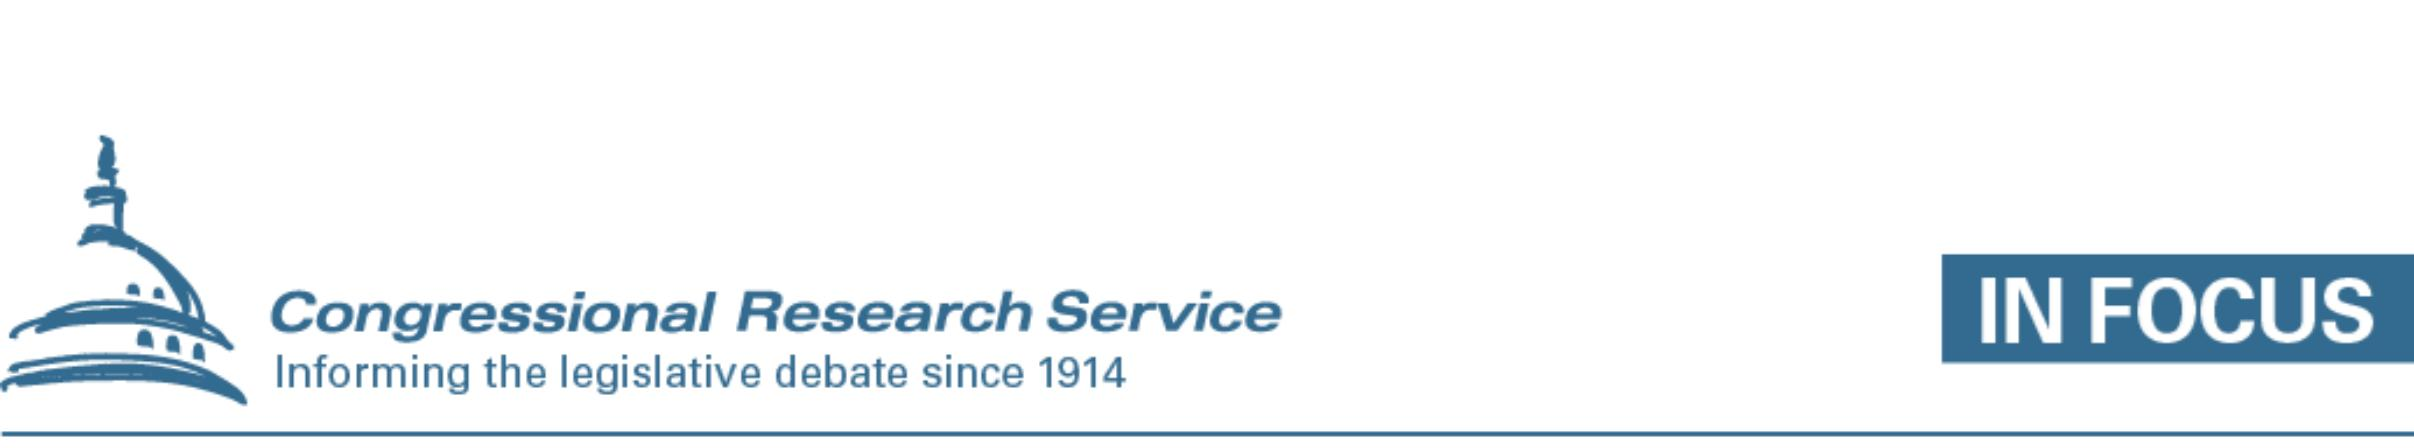

In [26]:
from IPython.display import Image

Image('./figures/figure-1-1.jpg')

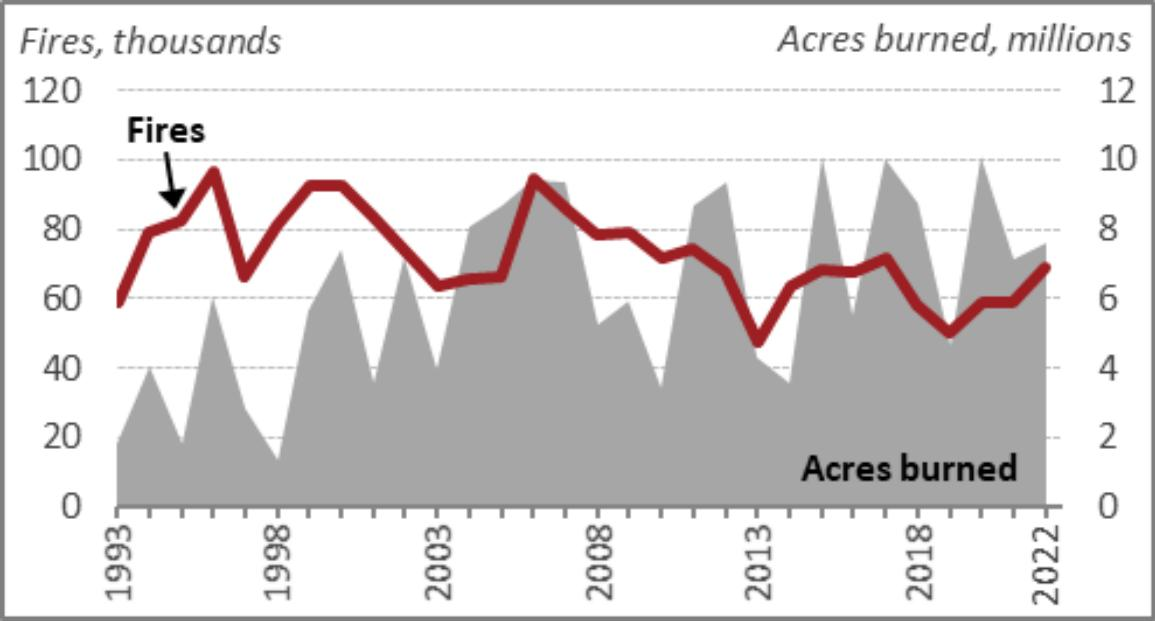

In [27]:
Image('./figures/figure-1-2.jpg')

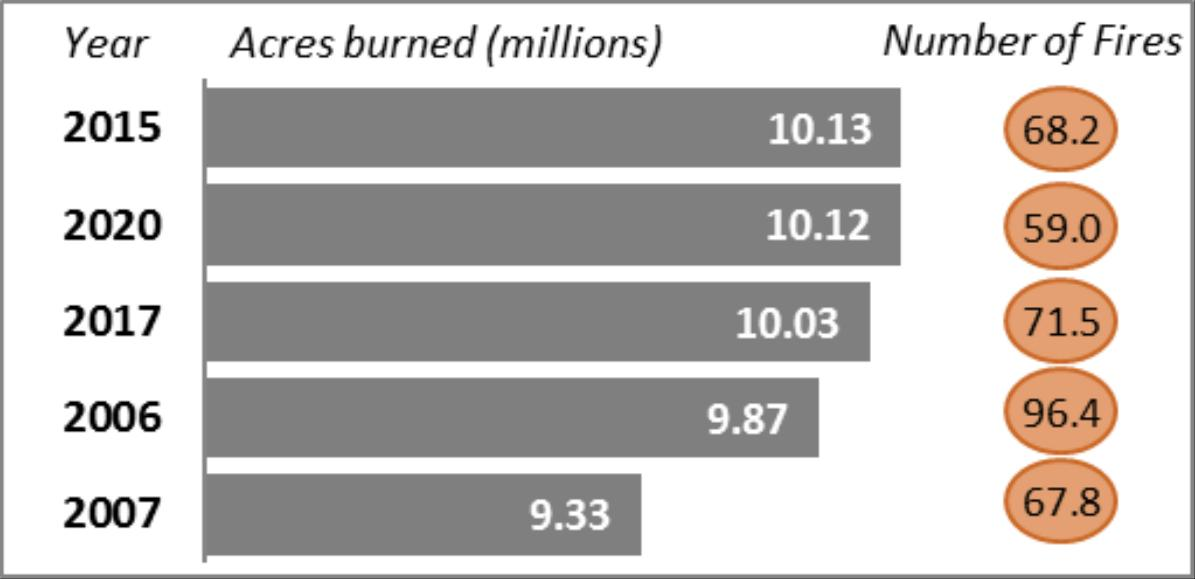

In [28]:
Image('./figures/figure-1-3.jpg')

### Enter Open AI API Key

In [29]:
from getpass import getpass

OPENAI_KEY = getpass('Enter Open AI API Key: ')

Enter Open AI API Key: ··········


### Setup Environment Variables

In [30]:
import os

os.environ['OPENAI_API_KEY'] = OPENAI_KEY

### Load Connection to LLM

Here we create a connection to ChatGPT to use later in our chains

In [31]:
from langchain_openai import ChatOpenAI

chatgpt = ChatOpenAI(model_name='gpt-4o-mini', temperature=0)



### Text and Table summaries

We will use GPT-4o-mini to produce table and, text summaries.

Text summaries are advised if using large chunk sizes (e.g., as set above, we use 4k token chunks).

Summaries are used to retrieve raw tables and / or raw chunks of text.

In [32]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.runnables import RunnablePassthrough

# Prompt
prompt_text = """
You are an assistant tasked with summarizing tables and text particularly for semantic retrieval.
These summaries will be embedded and used to retrieve the raw text or table elements
Give a detailed summary of the table or text below that is well optimized for retrieval.
For any tables also add in a one line description of what the table is about besides the summary.
Do not add redundant words like Summary.
Just output the actual summary content.

Table or text chunk:
{element}
"""
prompt = ChatPromptTemplate.from_template(prompt_text)

# Summary chain
summarize_chain = (
                    {"element": RunnablePassthrough()}
                      |
                    prompt
                      |
                    chatgpt
                      |
                    StrOutputParser() # extracts the response as text and returns it as a string
)

# Initialize empty summaries
text_summaries = []
table_summaries = []

text_docs = [doc.page_content for doc in docs]
table_docs = [table.page_content for table in tables]

text_summaries = summarize_chain.batch(text_docs, {"max_concurrency": 5})
table_summaries = summarize_chain.batch(table_docs, {"max_concurrency": 5})

len(text_summaries), len(table_summaries)

(5, 2)

In [33]:
text_summaries[0]

'This table presents statistics on wildfires in the U.S. from 1993 to 2022, detailing the number of wildfires and acres burned annually.\n\nWildfires are categorized as unplanned fires, including those caused by lightning, unauthorized human actions, and escaped prescribed burns. States manage wildfires on nonfederal lands, while the federal government oversees those on federal lands, with the Forest Service and the Department of the Interior responsible for significant areas. Data from the National Interagency Coordination Center shows that while the number of annual wildfires has slightly decreased over the past 30 years, the acreage burned has generally increased. From 2000 onwards, an average of 70,025 wildfires burned approximately 7.0 million acres annually, more than double the average from the 1990s. Between 2013 and 2022, the average was 61,410 wildfires and 7.2 million acres affected each year. In 2022, there were 68,988 wildfires, burning 7.6 million acres, with over 40% of 

In [34]:
table_summaries[0]

'This table presents data on the number of fires and acres burned in the United States from 2018 to 2022, categorized by federal and nonfederal sources.\n\nThe number of fires (in thousands) shows a total increase from 58.1 in 2018 to 69.0 in 2022, with federal fires fluctuating around 10-14, while nonfederal fires increased significantly from 45.6 to 57.2. The acres burned (in millions) also increased overall, with total acres burned rising from 8.8 in 2018 to 7.6 in 2022, despite a peak of 10.1 in 2020. Federal acres burned varied, peaking at 7.1 million in 2020, while nonfederal acres burned showed a notable increase in 2022.'

### Image summaries

We will use [GPT-4o-mini](https://openai.com/index/hello-gpt-4o/) to produce the image summaries.

* We pass base64 encoded images

In [35]:
import base64
import os

from langchain_core.messages import HumanMessage


def encode_image(image_path):
    """Getting the base64 string"""
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")


def image_summarize(img_base64, prompt):
    """Make image summary"""
    chat = ChatOpenAI(model="gpt-4o-mini", temperature=0)

    msg = chat.invoke(
        [
            HumanMessage(
                content=[
                    {"type": "text", "text": prompt},
                    {
                        "type": "image_url",
                        "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"},
                    },
                ]
            )
        ]
    )
    return msg.content


def generate_img_summaries(path):
    """
    Generate summaries and base64 encoded strings for images
    path: Path to list of .jpg files extracted by Unstructured
    """

    # Store base64 encoded images
    img_base64_list = []

    # Store image summaries
    image_summaries = []

    # Prompt
    prompt = """You are an assistant tasked with summarizing images for retrieval.
                Remember these images could potentially contain graphs, charts or tables also.
                These summaries will be embedded and used to retrieve the raw image for question answering.
                Give a detailed summary of the image that is well optimized for retrieval.
                Do not add additional words like Summary, This image represents, etc.
             """

    # Apply to images
    for img_file in sorted(os.listdir(path)):
        if img_file.endswith(".jpg"):
            img_path = os.path.join(path, img_file)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt))

    return img_base64_list, image_summaries


# Image summaries
IMG_PATH = './figures'
imgs_base64, image_summaries = generate_img_summaries(IMG_PATH)

In [36]:
len(imgs_base64), len(image_summaries)

(5, 5)

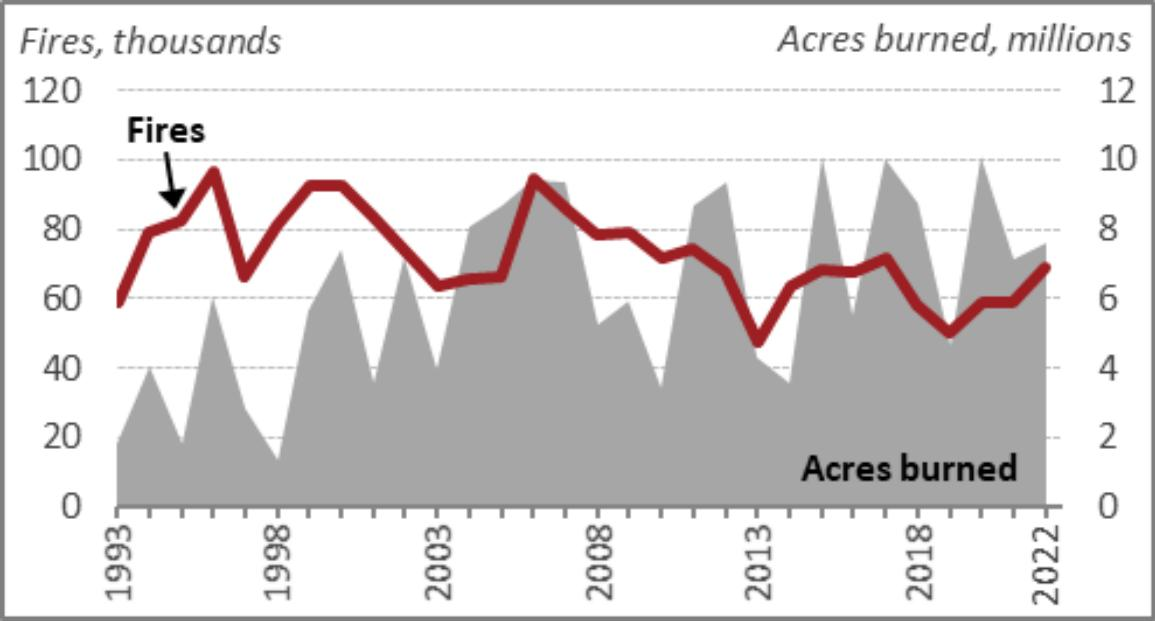

In [37]:
display(Image('./figures/figure-1-2.jpg'))

In [38]:
image_summaries[1]

'Line graph depicting the relationship between the number of fires (in thousands) and acres burned (in millions) from 1993 to 2022. The x-axis represents the years, while the left y-axis indicates the number of fires, and the right y-axis shows the acres burned. The red line illustrates the trend in the number of fires, showing fluctuations with a peak around 2006 and a general decline towards 2022. The gray area represents the acres burned, which shows a more stable trend with some peaks, particularly around 2006 and 2018, but generally remains below 10 million acres. The graph highlights the disparity between the number of fires and the total acres burned over the years.'

## Multi-vector retriever

Use [multi-vector-retriever](https://python.langchain.com/docs/modules/data_connection/retrievers/multi_vector#summary) to index image (and / or text, table) summaries, but retrieve raw images (along with raw texts or tables).

### Download and Install Redis as a DocStore

You can use any other database or cache as a docstore to store the raw text, table and image elements

In [39]:
%%sh
curl -fsSL https://packages.redis.io/gpg | sudo gpg --dearmor -o /usr/share/keyrings/redis-archive-keyring.gpg
echo "deb [signed-by=/usr/share/keyrings/redis-archive-keyring.gpg] https://packages.redis.io/deb $(lsb_release -cs) main" | sudo tee /etc/apt/sources.list.d/redis.list
sudo apt-get update  > /dev/null 2>&1
sudo apt-get install redis-stack-server  > /dev/null 2>&1
redis-stack-server --daemonize yes

deb [signed-by=/usr/share/keyrings/redis-archive-keyring.gpg] https://packages.redis.io/deb jammy main
Starting redis-stack-server, database path /var/lib/redis-stack


### Open AI Embedding Models

LangChain enables us to access Open AI embedding models which include the newest models: a smaller and highly efficient `text-embedding-3-small` model, and a larger and more powerful `text-embedding-3-large` model.

In [40]:
from langchain_openai import OpenAIEmbeddings

# details here: https://openai.com/blog/new-embedding-models-and-api-updates
openai_embed_model = OpenAIEmbeddings(model='text-embedding-3-small')

In [41]:
docs[0]

Document(metadata={'source': '/content/IF10244.pdf', 'filetype': 'application/pdf', 'languages': ['eng'], 'last_modified': '2026-03-20T09:32:08', 'page_number': 1, 'orig_elements': 'eJzNWN9v4zYS/lcIAwUSwFJJiqLIvOWy2CJ9SIvLFvewtzAoibLZypKgH9n1FXd/+82QsuN4vcVtAB/yklgjznA4M5zvG338c2Fru7XNuHLl4oYsOMuMtjyPUppXkbAyj0yVVlFS5qlVpahMaRZLstjaEX6NBnT+XBRt25euMaMd/HNtdu00rjbWrTcjSBKVUtCZxZ9dOW5AynWWgrRrXTOi3sePXNEYFiax+LQk+yeR0lj7Z6lFnJ4R4Hp4Xgy7YbRbPMWv7outHztT2MW/4UXlajvuOutfPfyE/rutWdtVZ7wnix+LthkhCD9Wbj31dpj/Ryxi8e/deuGdb9YT6HhPF7ZZLz556TCutm3pKmdD/CiXEU0iTj9QfZPwG6pQu8Pdmmmb2x5WMXRqtF8wNot/TpwysfrPitw3VdtvXbMm48aS2q7dUJvRPVlS2hyCSwbXFJYwzQS5a5s1ODq4tjE1+bsdrOmLDXm0/ZODU6P9+cD3eFIMw2mqlRJlwqyMeK5oJAQ1Ua5ZFpVUm8pUuahEeblUQ/JijsmUsfLJnAUpVTH3gozSWJ4RBJW/THhpR1uMEJtVARkaVl3f5rCMxinlin+jIoYVZKQ3xRgyOfaTvWjif+sgqrYkP08NJHVJwEJynLgH0/c+/R9Q4UwCRVoxoU0WCZnlkaA5jSB/JlJFXlaFUTZn6tJ3NWUilke3VTL4h886TeLs6+ew/nXJU0JnbyV5/3B1WbnekscRcjSMrhiOc/fBjfXZS5dLzU2lkojxSkHidAXpknDzbFlayfMiM+mlcyalnG9UeGaC6jhFARPyG5

### Add to vectorstore & docstore

Add raw docs and doc summaries to [Multi Vector Retriever](https://python.langchain.com/docs/modules/data_connection/retrievers/multi_vector#summary):

* Store the raw texts, tables, and images in the `docstore` (here we are using Redis).
* Store the texts, table summaries, and image summaries and their corresponding embeddings in the `vectorstore` (here we are using Chroma) for efficient semantic retrieval.
* Connect them using a common `document_id`

In [42]:
import uuid

from langchain_classic.retrievers import MultiVectorRetriever
from langchain_community.storage import RedisStore
from langchain_community.utilities.redis import get_client
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_openai import OpenAIEmbeddings


def create_multi_vector_retriever(
    docstore, vectorstore, text_summaries, texts, table_summaries, tables, image_summaries, images
):
    """
    Create retriever that indexes summaries, but returns raw images or texts
    """


    id_key = "doc_id"

    # Create the multi-vector retriever
    retriever = MultiVectorRetriever(
        vectorstore=vectorstore,
        docstore=docstore,
        id_key=id_key,
    )

    # Helper function to add documents to the vectorstore and docstore
    def add_documents(retriever, doc_summaries, doc_contents):
        doc_ids = [str(uuid.uuid4()) for _ in doc_contents]
        summary_docs = [
            Document(page_content=s, metadata={id_key: doc_ids[i]})
            for i, s in enumerate(doc_summaries)
        ]
        retriever.vectorstore.add_documents(summary_docs)
        retriever.docstore.mset(list(zip(doc_ids, doc_contents)))

    # Add texts, tables, and images
    # Check that text_summaries is not empty before adding
    if text_summaries:
        add_documents(retriever, text_summaries, texts)
    # Check that table_summaries is not empty before adding
    if table_summaries:
        add_documents(retriever, table_summaries, tables)
    # Check that image_summaries is not empty before adding
    if image_summaries:
        add_documents(retriever, image_summaries, images)

    return retriever


# The vectorstore to use to index the summaries and their embeddings
chroma_db = Chroma(
    collection_name="mm_rag",
    embedding_function=openai_embed_model,
    collection_metadata={"hnsw:space": "cosine"},
)

# Initialize the storage layer - to store raw images, text and tables
client = get_client('redis://localhost:6379')
redis_store = RedisStore(client=client) # you can use filestore, memorystory, any other DB store also

# Create retriever
retriever_multi_vector = create_multi_vector_retriever(
    redis_store,
    chroma_db,
    text_summaries,
    text_docs,
    table_summaries,
    table_docs,
    image_summaries,
    imgs_base64,
)

In [43]:
retriever_multi_vector

MultiVectorRetriever(vectorstore=<langchain_chroma.vectorstores.Chroma object at 0x7b7ce71b6a80>, docstore=<langchain_community.storage.redis.RedisStore object at 0x7b7ce6f0ea80>, search_kwargs={})

## Test Multimodal RAG Retriever



In [44]:
from IPython.display import display
from PIL import Image
import base64
from io import BytesIO

def plt_img_base64(doc):
    # Get base64 from metadata, not page_content
    img_b64 = doc.metadata.get('image_base64') or doc.page_content
    img_data = base64.b64decode(img_b64.strip())
    img = Image.open(BytesIO(img_data))
    display(img)

In [45]:
from IPython.display import display
from PIL import Image
import base64
from io import BytesIO

def plt_img_base64(doc):
    """Display an image from a Document object or base64 string."""

    # Try metadata first (where Unstructured stores image data)
    img_b64 = None

    if hasattr(doc, 'metadata'):
        img_b64 = doc.metadata.get('image_base64')

    # Fall back to page_content if no metadata image
    if not img_b64:
        if hasattr(doc, 'page_content'):
            img_b64 = doc.page_content
        elif isinstance(doc, str):
            img_b64 = doc

    if not img_b64:
        raise ValueError("No image data found in document")

    # Clean up base64 string
    img_b64 = img_b64.strip()
    if img_b64.startswith("data:image"):
        img_b64 = img_b64.split(",", 1)[1]

    img_data = base64.b64decode(img_b64)
    img = Image.open(BytesIO(img_data))
    display(img)


# Filter only image elements
image_docs = [doc for doc in data if doc.metadata.get('category') == 'Image']
print(f"Found {len(image_docs)} image(s)")

# Display all images
for i, doc in enumerate(image_docs):
    print(f"\n--- Image {i+1} (page {doc.metadata.get('page_number', '?')}) ---")
    plt_img_base64(doc)

Found 0 image(s)


### Check Retrieval

Examine retrieval; we get back images and tables also that are relevant to our question.

In [46]:
# Check retrieval
query = "Analyze the wildfires trend with acres burned over the years"
docs = retriever_multi_vector.invoke(query, limit=5)

# We get 3 docs
len(docs)

4

In [47]:
docs

[b'...',
 b'Figure 2. Top Five Years with Largest Wildfire Acreage Burned Since 1960\n\nTable 1. Annual Wildfires and Acres Burned\n\n2018 2019 2020 Number of Fires (thousands) Federal 12.5 10.9 14.4 FS 5.6 5.3 6.7 DOI 7.0 5.3 7.6 2021 14.0 6.2 7.6 11.7 5.9 5.8 Other 0.1 0.2 <0.1 0.2 0.1 Nonfederal 45.6 39.6 44.6 45.0 57.2 Total 58.1 50.5 59.0 59.0 69.0 Acres Burned (millions) Federal 4.6 3.1 7.1 5.2 4.0 FS 2.3 0.6 4.8 4.1 1.9 DOI 2.3 2.3 2.3 1.0 2.1 Other <0.1 <0.1 <0.1 <0.1 <0.1 Nonfederal 4.1 1.6 3.1 1.9 3.6 Total 8.8 4.7 10.1 7.1 7.6\n\nSource: National Interagency Coordination Center (NICC) Wildland Fire Summary and Statistics annual reports. Notes: FS = Forest Service; DOI = Department of the Interior. Column totals may not sum precisely due to rounding.\n\n2022\n\nYear Number of Fires 2015 Acres burned (millions) 2020 2017 2006 2007\n\nSource: NICC Wildland Fire Summary and Statistics annual reports. Note: Number of fires in thousands.\n\nThe number of fires and acreage burned a

In [49]:
# Check retrieval
query = "Tell me about the percentage of residences burned by wildfires in 2022"
docs = retriever_multi_vector.invoke(query, limit=5)

# We get 4 docs
len(docs)

4

In [50]:
docs

[b'|  | 2019 | 2020 | 2021 | 2022 |\n| :--- | :--- | :--- | :--- | :--- |\n| Structures Burned | 963 | 17,904 | 5,972 | 2,717 |\n| % Residences | 46% | 54% | 60% | 46% |\n',
 b'Figure 4. Acreage Burned by Region and Ownership\n\nAcres burned, millions East Nonfederal East Federal West Nonfederal West Federal 2018 2019 2020 2021 2022\n\n2019 2020 2021 2022 Structures Burned 963 17,904 5,972 2,717 % Residences 46% 54% 60% 46%\n\nSource: NICC Wildland Fire Summary and Statistics annual reports.\n\nConflagrations\n\nOf the 1.6 million wildfires that have occurred since 2000, 254 exceeded 100,000 acres burned and 16 exceeded 500,000 acres burned. A small fraction of wildfires become catastrophic, and a small percentage of fires accounts for the vast majority of acres burned. For example, about 1% of wildfires become conflagrations\xe2\x80\x94raging, destructive fires\xe2\x80\x94but predicting which fires will \xe2\x80\x9cblow up\xe2\x80\x9d into conflagrations is challenging and depends on 

## Utilities to separate retrieved elements

We need to bin the retrieved doc(s) into the correct parts of the GPT-4o-mini prompt template.

Here we need to have text, table elements as one set of inputs and image elements as the other set of inputs as both require separate prompts in GPT-4o-mini.

In [51]:
import re
import base64

def looks_like_base64(sb):
    """Check if the string looks like base64"""
    return re.match("^[A-Za-z0-9+/]+[=]{0,2}$", sb) is not None


def is_image_data(b64data):
    """
    Check if the base64 data is an image by looking at the start of the data
    """
    image_signatures = {
        b"\xff\xd8\xff": "jpg",
        b"\x89\x50\x4e\x47\x0d\x0a\x1a\x0a": "png",
        b"\x47\x49\x46\x38": "gif",
        b"\x52\x49\x46\x46": "webp",
    }
    try:
        header = base64.b64decode(b64data)[:8]  # Decode and get the first 8 bytes
        for sig, format in image_signatures.items():
            if header.startswith(sig):
                return True
        return False
    except Exception:
        return False


def split_image_text_types(docs):
    """
    Split base64-encoded images and texts
    """
    b64_images = []
    texts = []
    for doc in docs:
        # Check if the document is of type Document and extract page_content if so
        if isinstance(doc, Document):
            doc = doc.page_content.decode('utf-8')
        else:
            doc = doc.decode('utf-8')
        if looks_like_base64(doc) and is_image_data(doc):
            b64_images.append(doc)
        else:
            texts.append(doc)
    return {"images": b64_images, "texts": texts}

In [52]:
# Check retrieval
query = "Tell me detailed statistics of the top 5 years with largest wildfire acres burned"
docs = retriever_multi_vector.invoke(query, limit=5)

# We get 3 docs
len(docs)

4

In [53]:
docs

[b'...',
 b'\xe2\x80\x94_~_ Informing the legislative debate since 1914 Congressional Research Service\n\nUpdated June 1, 2023\n\nWildfire Statistics\n\nWildfires are unplanned fires, including lightning-caused fires, unauthorized human-caused fires, and escaped fires from prescribed burn projects. States are responsible for responding to wildfires that begin on nonfederal (state, local, and private) lands, except for lands protected by federal agencies under cooperative agreements. The federal government is responsible for responding to wildfires that begin on federal lands. The Forest Service (FS)\xe2\x80\x94within the U.S. Department of Agriculture\xe2\x80\x94carries out wildfire management and response across the 193 million acres of the National Forest System (NFS). The Department of the Interior (DOI) manages wildfire response for more than 400 million acres of national parks, wildlife refuges and preserves, other public lands, and Indian reservations.\n\nFigure 1. Annual Wildfir

In [54]:
is_image_data(docs[2].decode('utf-8'))

False

In [55]:
r = split_image_text_types(docs)
r

{'images': ['...'],
 'texts': ['—_~_ Informing the legislative debate since 1914 Congressional Research Service\n\nUpdated June 1, 2023\n\nWildfire Statistics\n\nWildfires are unplanned fires, including lightning-caused fires, unauthorized human-caused fires, and escaped fires from prescribed burn projects. States are responsible for responding to wildfires that begin on nonfederal (state, local, and private) lands, except for lands protected by federal agencies under cooperative agreements. The federal government is responsible for responding to wildfires that begin on federal lands. The Forest Service (FS)—within the U.S. Department of Agriculture—carries out wildfire management and response across the 193 million acres of the National Forest System (NFS). The Department of the Interior (DOI) manages wildfire response for more than 400 million acres of national parks, wildlife refuges and preserves, other public lands, and Indian reservations.\n\nFigure 1. Annual Wildfires and Acres 

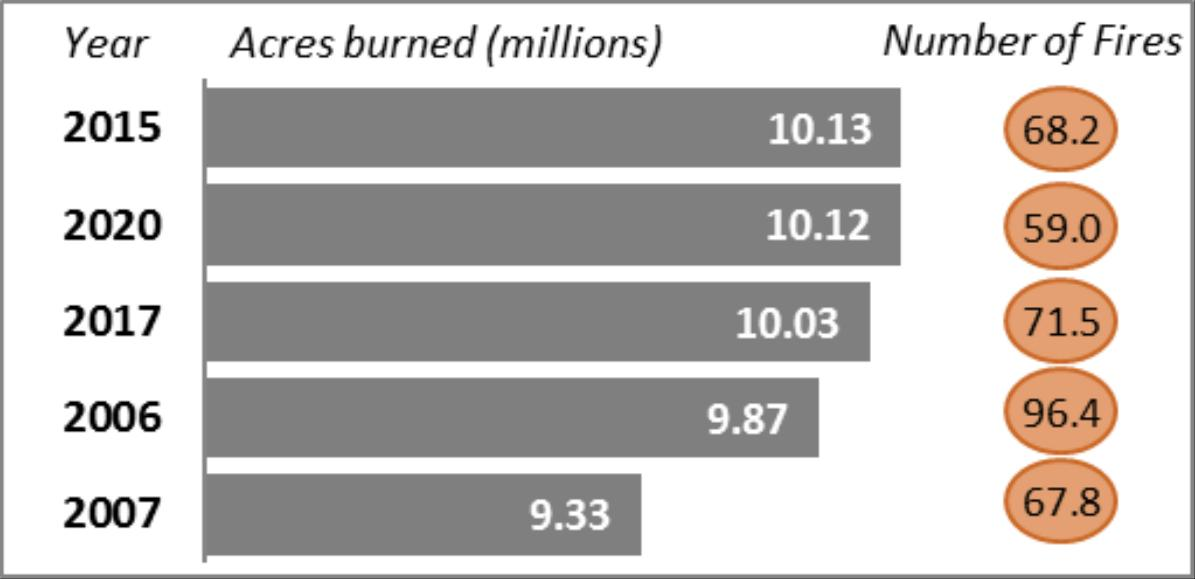

In [56]:
plt_img_base64(r['images'][0])

## Multimodal RAG

### Build End-to-End Multimodal RAG Pipeline

Now let's connect our retriever, prompt instructions and build a multimodal RAG chain

In [57]:
from operator import itemgetter
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_core.messages import HumanMessage

def multimodal_prompt_function(data_dict):
    """
    Create a multimodal prompt with both text and image context.

    This function formats the provided context from `data_dict`, which contains
    text, tables, and base64-encoded images. It joins the text (with table) portions
    and prepares the image(s) in a base64-encoded format to be included in a message.

    The formatted text and images (context) along with the user question are used to
    construct a prompt for GPT-4o-mini
    """
    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages = []

    # Adding image(s) to the messages if present
    if data_dict["context"]["images"]:
        for image in data_dict["context"]["images"]:
            image_message = {
                "type": "image_url",
                "image_url": {"url": f"data:image/jpeg;base64,{image}"},
            }
            messages.append(image_message)

    # Adding the text and tables for analysis
    text_message = {
        "type": "text",
        "text": (
            f"""You are an analyst tasked with understanding detailed information and trends
                from text documents, data tables, and charts and graphs in images.
                You will be given context information below which will be a mix of text, tables,
                and images usually of charts or graphs.
                Use this information to provide answers related to the user question.
                Analyze all the context information including tables, text and images to generate the answer.
                Do not make up answers, use the provided context documents below
                and answer the question to the best of your ability.

                User question:
                {data_dict['question']}

                Context documents:
                {formatted_texts}

                Answer:
            """
        ),
    }
    messages.append(text_message)
    return [HumanMessage(content=messages)]


# Create RAG chain
multimodal_rag = (
        {
            "context": itemgetter('context'),
            "question": itemgetter('input'),
        }
            |
        RunnableLambda(multimodal_prompt_function)
            |
        chatgpt
            |
        StrOutputParser()
)

# Pass input query to retriever and get context document elements
retrieve_docs = (itemgetter('input')
                    |
                retriever_multi_vector
                    |
                RunnableLambda(split_image_text_types))

# Below, we chain `.assign` calls. This takes a dict and successively
# adds keys-- "context" and "answer"-- where the value for each key
# is determined by a Runnable (function or chain executing at runtime).
# This helps in also having the retrieved context along with the answer generated by GPT-4o
multimodal_rag_w_sources = (RunnablePassthrough.assign(context=retrieve_docs)
                                               .assign(answer=multimodal_rag)
)

In [58]:
# Run RAG chain
query = "Tell me detailed statistics of the top 5 years with largest wildfire acres burned"
response = multimodal_rag_w_sources.invoke({'input': query})
response

{'input': 'Tell me detailed statistics of the top 5 years with largest wildfire acres burned',
 'context': {'images': ['...'],
  'texts': ['—_~_ Informing the legislative debate since 1914 Congressional Research Service\n\nUpdated June 1, 2023\n\nWildfire Statistics\n\nWildfires are unplanned fires, including lightning-caused fires, unauthorized human-caused fires, and escaped fires from prescribed burn projects. States are responsible for responding to wildfires that begin on nonfederal (state, local, and private) lands, except for lands protected by federal agencies under cooperative agreements. The federal government is responsible for responding to wildfires that begin on federal lands. The Forest Service (FS)—within the U.S. Department of Agriculture—carries out wildfire management and response across the 193 million acres of the National Forest System (NFS). The Department of the Interior (DOI) manages wildfire response for more than 400 million acres of national parks, wildlife 

In [59]:
def multimodal_rag_qa(query):
    response = multimodal_rag_w_sources.invoke({'input': query})
    print('=='*50)
    print('Answer:')
    display(Markdown(response['answer']))
    print('--'*50)
    print('Sources:')
    text_sources = response['context']['texts']
    img_sources = response['context']['images']
    for text in text_sources:
        display(Markdown(text))
        print()
    for img in img_sources:
        plt_img_base64(img)
        print()
    print('=='*50)

Answer:


The top five years with the largest wildfire acreage burned, based on the provided data, are as follows:

1. **2015**: 
   - **Acres burned**: 10.13 million
   - **Number of fires**: 68.2 thousand

2. **2020**: 
   - **Acres burned**: 10.12 million
   - **Number of fires**: 59.0 thousand

3. **2017**: 
   - **Acres burned**: 10.03 million
   - **Number of fires**: 71.5 thousand

4. **2006**: 
   - **Acres burned**: 9.87 million
   - **Number of fires**: 96.4 thousand

5. **2007**: 
   - **Acres burned**: 9.33 million
   - **Number of fires**: 67.8 thousand

These statistics highlight the significant impact of wildfires in these years, with 2015 and 2020 being the most severe in terms of acreage burned.

----------------------------------------------------------------------------------------------------
Sources:


—_~_ Informing the legislative debate since 1914 Congressional Research Service

Updated June 1, 2023

Wildfire Statistics

Wildfires are unplanned fires, including lightning-caused fires, unauthorized human-caused fires, and escaped fires from prescribed burn projects. States are responsible for responding to wildfires that begin on nonfederal (state, local, and private) lands, except for lands protected by federal agencies under cooperative agreements. The federal government is responsible for responding to wildfires that begin on federal lands. The Forest Service (FS)—within the U.S. Department of Agriculture—carries out wildfire management and response across the 193 million acres of the National Forest System (NFS). The Department of the Interior (DOI) manages wildfire response for more than 400 million acres of national parks, wildlife refuges and preserves, other public lands, and Indian reservations.

Figure 1. Annual Wildfires and Acres Burned, 1993-2022

Fires, thousands Acres burned, millions 120 Fires 4

Wildfire statistics help illustrate past U.S. wildfire activity. Nationwide data compiled by the National Interagency Coordination Center (NICC) indicate that the number of annual wildfires is variable but has decreased slightly over the last 30 years. The number of acres affected annually, while also variable, generally has increased (see Figure 1). Since 2000, an annual average of 70,025 wildfires have burned an annual average of 7.0 million acres. The acreage figure is more than double the average annual acreage burned in the 1990s (3.3 million acres), although a greater number of fires occurred annually in the 1990s on average (78,600).

Source: NICC Wildland Fire Summary and Statistics annual reports. Note: Data reflect wildland fires and acres burned nationwide, including wildland fires on federal and nonfederal lands.

From 2013 to 2022, there were an average of 61,410 wildfires annually and an average of 7.2 million acres impacted annually. In 2022, 68,988 wildfires burned 7.6 million acres. Over 40% of those acres were in Alaska (3.1 million acres).

As of June 1, 2023, around 18,300 wildfires have impacted over 511,000 acres this year.

Figure 4. Acreage Burned by Region and Ownership

Acres burned, millions East Nonfederal East Federal West Nonfederal West Federal 2018 2019 2020 2021 2022

2019 2020 2021 2022 Structures Burned 963 17,904 5,972 2,717 % Residences 46% 54% 60% 46%

Source: NICC Wildland Fire Summary and Statistics annual reports.

Conflagrations

Of the 1.6 million wildfires that have occurred since 2000, 254 exceeded 100,000 acres burned and 16 exceeded 500,000 acres burned. A small fraction of wildfires become catastrophic, and a small percentage of fires accounts for the vast majority of acres burned. For example, about 1% of wildfires become conflagrations—raging, destructive fires—but predicting which fires will “blow up” into conflagrations is challenging and depends on a multitude of factors, such as weather and geography. There have been 1,041 large or significant fires annually on average from 2018 through 2022. In 2022, 2% of wildfires were classified as large or significant (1,289); 45 exceeded 40,000 acres in size, and 17 exceeded 100,000 acres. For context, there were fewer large or significant wildfires in 2021 (943) but more in 2017 (1,409).

Issues for Congress

Issues Congress may consider include the strategies and resources used for wildfire prevention, mitigation, and management, as well as wildfires’ impact on both the quality of life and the economies of communities affected by wildfire activity. Other issues relate to post-wildfire recovery and site restoration. Congress also considers the total federal cost of wildfire management, including the cost of suppression operations; these costs vary annually and are difficult to predict.

Source: NICC Wildland Fire Summary and Statistics annual reports. Notes: West: AK, AZ, CA, CO, ID, HI, MT, NM, NV, OR, UT, WA, and WY. East: All other states and Puerto Rico.

Katie Hoover, Specialist in Natural Resources Policy Laura A. Hanson, Senior Research Librarian

IF10244

https://crsreports.congress.gov

Wildfire Statistics

Figure 2. Top Five Years with Largest Wildfire Acreage Burned Since 1960

Table 1. Annual Wildfires and Acres Burned

2018 2019 2020 Number of Fires (thousands) Federal 12.5 10.9 14.4 FS 5.6 5.3 6.7 DOI 7.0 5.3 7.6 2021 14.0 6.2 7.6 11.7 5.9 5.8 Other 0.1 0.2 <0.1 0.2 0.1 Nonfederal 45.6 39.6 44.6 45.0 57.2 Total 58.1 50.5 59.0 59.0 69.0 Acres Burned (millions) Federal 4.6 3.1 7.1 5.2 4.0 FS 2.3 0.6 4.8 4.1 1.9 DOI 2.3 2.3 2.3 1.0 2.1 Other <0.1 <0.1 <0.1 <0.1 <0.1 Nonfederal 4.1 1.6 3.1 1.9 3.6 Total 8.8 4.7 10.1 7.1 7.6

Source: National Interagency Coordination Center (NICC) Wildland Fire Summary and Statistics annual reports. Notes: FS = Forest Service; DOI = Department of the Interior. Column totals may not sum precisely due to rounding.

2022

Year Number of Fires 2015 Acres burned (millions) 2020 2017 2006 2007

Source: NICC Wildland Fire Summary and Statistics annual reports. Note: Number of fires in thousands.

The number of fires and acreage burned are indicators of the annual level of wildfire activity. These numbers may not be indicative of fire’s impact on human development or communities, since many fires occur in large, relatively undeveloped areas. Acreage burned also does not indicate the severity of a wildfire, the degree of impact upon forests or soils, or other ecological effects.

Most wildfires are human-caused (89% of the average number of wildfires from 2018 to 2022). Wildfires caused by lightning tend to be slightly larger and to burn more acreage (53% of the average acreage burned from 2018 to 2022) than human-caused fires.

https://crsreports.congress.gov

Wildfire Statistics

In 2022, 52% of the nationwide acreage burned by wildfires was on federal lands (4.0 million acres; see Table 1), lower than the 10-year average (64%) of impacted federal land acreage. The other 48% of the acreage burned in 2022 was on state, local, or privately owned lands, though the fires on these lands accounted for 83% of total fires. Of the federal acreage burned nationwide in 2022, 52% (2.1 million acres) burned on DOI land and 47% (1.9 million acres) burned on FS land (see Figure 3). The 2022 figures are driven largely by Alaska, where just over half of the acreage impacted occurred on nonfederal lands (1.6 million acres) and just under half was on DOI lands (1.5 million acres).

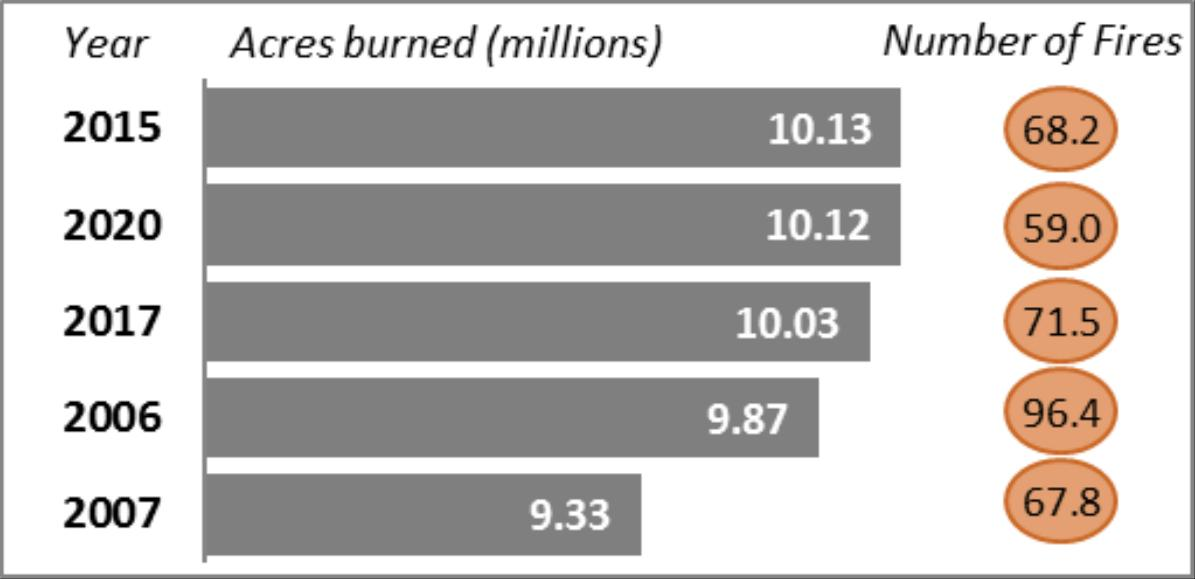

In [60]:
query = "Tell me detailed statistics of the top 5 years with largest wildfire acres burned"
multimodal_rag_qa(query)

Answer:


The analysis of wildfire trends based on the provided data reveals several key insights regarding the number of wildfires and the acreage burned over the years.

### General Trends:
1. **Number of Wildfires**:
   - The number of wildfires has shown a slight decrease over the past 30 years. For instance, the average number of wildfires from 2013 to 2022 was approximately 61,410 annually, compared to an average of 78,600 in the 1990s.

2. **Acreage Burned**:
   - In contrast to the decreasing number of fires, the acreage burned has generally increased. The average annual acreage burned from 2000 to 2022 was about 7.0 million acres, which is significantly higher than the 3.3 million acres burned on average in the 1990s.
   - In 2022, 68,988 wildfires burned approximately 7.6 million acres, with over 40% of those acres located in Alaska.

### Specific Year Analysis:
- **Top Years for Acreage Burned**:
  - The years 2015, 2017, and 2020 stand out with over 10 million acres burned, as indicated in the second image. Specifically:
    - 2015: 10.13 million acres burned with 68.2 thousand fires.
    - 2020: 10.12 million acres burned with 59.0 thousand fires.
    - 2017: 10.03 million acres burned with 71.5 thousand fires.

- **Comparison of Fires and Acreage**:
  - The data shows that while the number of fires can fluctuate, the acreage burned tends to be more consistent in its upward trend. For example, in 2006, there were 96.4 thousand fires, but only 9.87 million acres burned, indicating that not all fires result in extensive acreage burned.

### Federal vs. Nonfederal Lands:
- In 2022, 52% of the acreage burned was on federal lands, which is lower than the 10-year average of 64%. This indicates a shift in where wildfires are impacting land, with a significant portion occurring on state, local, or privately owned lands.

### Conclusion:
The data illustrates a complex relationship between the number of wildfires and the acreage burned. While the frequency of wildfires has decreased slightly, the severity and impact, as measured by acreage burned, have increased significantly over the years. This trend highlights the growing challenge of managing wildfires, particularly in the context of climate change and land management practices.

----------------------------------------------------------------------------------------------------
Sources:


Figure 2. Top Five Years with Largest Wildfire Acreage Burned Since 1960

Table 1. Annual Wildfires and Acres Burned

2018 2019 2020 Number of Fires (thousands) Federal 12.5 10.9 14.4 FS 5.6 5.3 6.7 DOI 7.0 5.3 7.6 2021 14.0 6.2 7.6 11.7 5.9 5.8 Other 0.1 0.2 <0.1 0.2 0.1 Nonfederal 45.6 39.6 44.6 45.0 57.2 Total 58.1 50.5 59.0 59.0 69.0 Acres Burned (millions) Federal 4.6 3.1 7.1 5.2 4.0 FS 2.3 0.6 4.8 4.1 1.9 DOI 2.3 2.3 2.3 1.0 2.1 Other <0.1 <0.1 <0.1 <0.1 <0.1 Nonfederal 4.1 1.6 3.1 1.9 3.6 Total 8.8 4.7 10.1 7.1 7.6

Source: National Interagency Coordination Center (NICC) Wildland Fire Summary and Statistics annual reports. Notes: FS = Forest Service; DOI = Department of the Interior. Column totals may not sum precisely due to rounding.

2022

Year Number of Fires 2015 Acres burned (millions) 2020 2017 2006 2007

Source: NICC Wildland Fire Summary and Statistics annual reports. Note: Number of fires in thousands.

The number of fires and acreage burned are indicators of the annual level of wildfire activity. These numbers may not be indicative of fire’s impact on human development or communities, since many fires occur in large, relatively undeveloped areas. Acreage burned also does not indicate the severity of a wildfire, the degree of impact upon forests or soils, or other ecological effects.

Most wildfires are human-caused (89% of the average number of wildfires from 2018 to 2022). Wildfires caused by lightning tend to be slightly larger and to burn more acreage (53% of the average acreage burned from 2018 to 2022) than human-caused fires.

https://crsreports.congress.gov

Wildfire Statistics

In 2022, 52% of the nationwide acreage burned by wildfires was on federal lands (4.0 million acres; see Table 1), lower than the 10-year average (64%) of impacted federal land acreage. The other 48% of the acreage burned in 2022 was on state, local, or privately owned lands, though the fires on these lands accounted for 83% of total fires. Of the federal acreage burned nationwide in 2022, 52% (2.1 million acres) burned on DOI land and 47% (1.9 million acres) burned on FS land (see Figure 3). The 2022 figures are driven largely by Alaska, where just over half of the acreage impacted occurred on nonfederal lands (1.6 million acres) and just under half was on DOI lands (1.5 million acres).

—_~_ Informing the legislative debate since 1914 Congressional Research Service

Updated June 1, 2023

Wildfire Statistics

Wildfires are unplanned fires, including lightning-caused fires, unauthorized human-caused fires, and escaped fires from prescribed burn projects. States are responsible for responding to wildfires that begin on nonfederal (state, local, and private) lands, except for lands protected by federal agencies under cooperative agreements. The federal government is responsible for responding to wildfires that begin on federal lands. The Forest Service (FS)—within the U.S. Department of Agriculture—carries out wildfire management and response across the 193 million acres of the National Forest System (NFS). The Department of the Interior (DOI) manages wildfire response for more than 400 million acres of national parks, wildlife refuges and preserves, other public lands, and Indian reservations.

Figure 1. Annual Wildfires and Acres Burned, 1993-2022

Fires, thousands Acres burned, millions 120 Fires 4

Wildfire statistics help illustrate past U.S. wildfire activity. Nationwide data compiled by the National Interagency Coordination Center (NICC) indicate that the number of annual wildfires is variable but has decreased slightly over the last 30 years. The number of acres affected annually, while also variable, generally has increased (see Figure 1). Since 2000, an annual average of 70,025 wildfires have burned an annual average of 7.0 million acres. The acreage figure is more than double the average annual acreage burned in the 1990s (3.3 million acres), although a greater number of fires occurred annually in the 1990s on average (78,600).

Source: NICC Wildland Fire Summary and Statistics annual reports. Note: Data reflect wildland fires and acres burned nationwide, including wildland fires on federal and nonfederal lands.

From 2013 to 2022, there were an average of 61,410 wildfires annually and an average of 7.2 million acres impacted annually. In 2022, 68,988 wildfires burned 7.6 million acres. Over 40% of those acres were in Alaska (3.1 million acres).

As of June 1, 2023, around 18,300 wildfires have impacted over 511,000 acres this year.

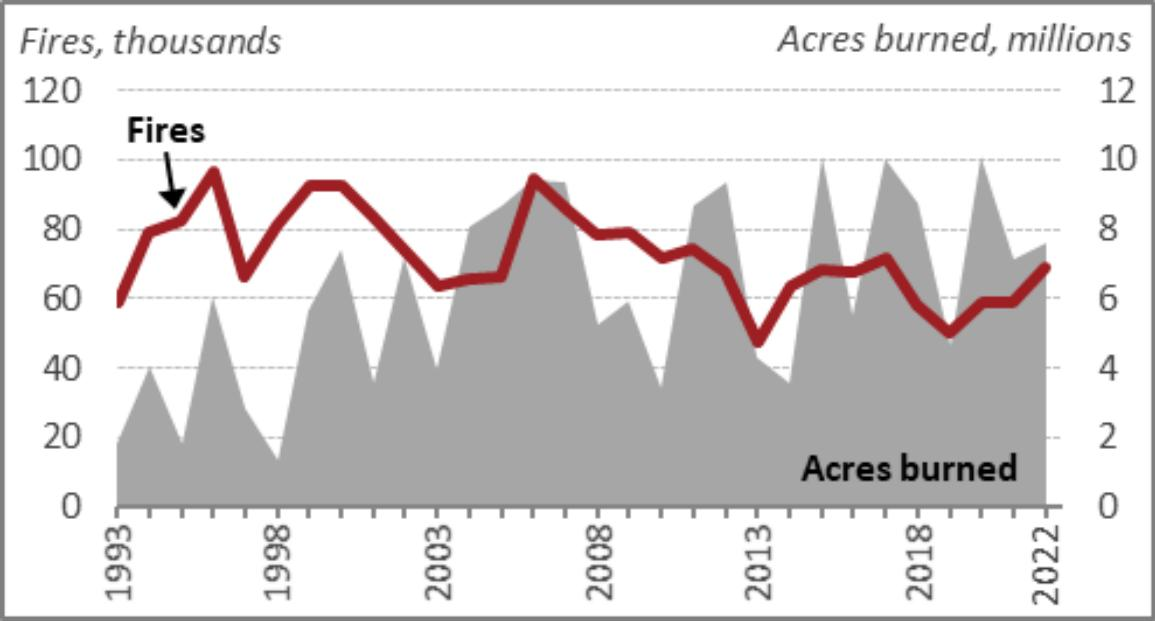

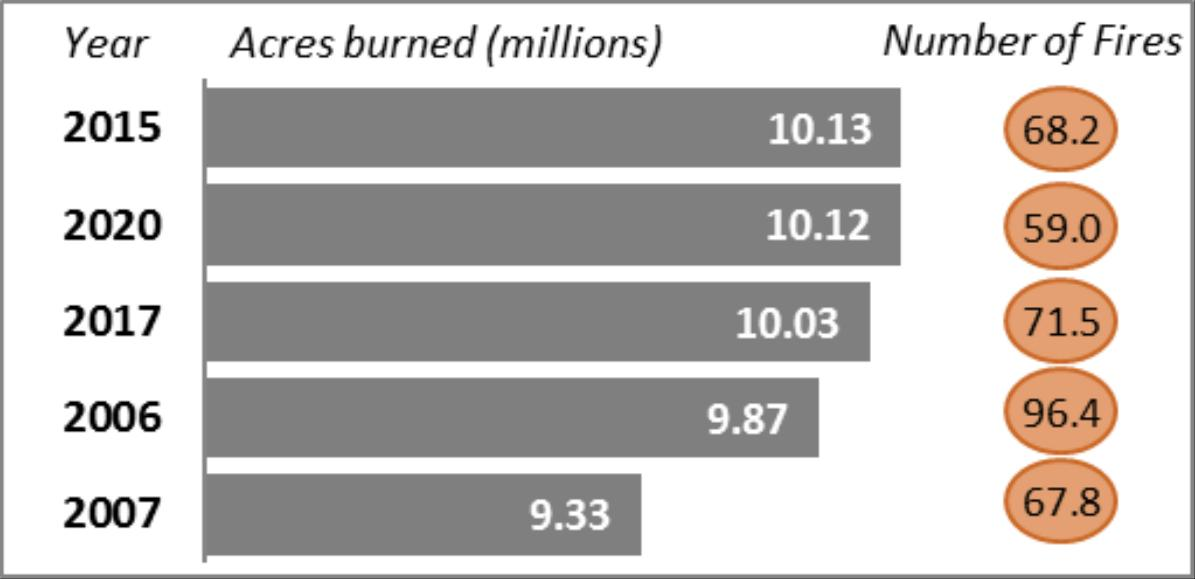

In [61]:
# Run RAG chain
query = "Analyze the wildfires trend with acres burned over the years"
multimodal_rag_qa(query)

In [62]:
# Run RAG chain
query = "Tell me about the percentage of residences burned by wildfires in 2022"
multimodal_rag_qa(query)

Answer:


In 2022, the percentage of residences burned by wildfires was 46%. This percentage is derived from the total structures burned, which amounted to 2,717, with 46% of those being residences. This marks a decrease from the previous year, 2021, when 60% of the structures burned were residences.

----------------------------------------------------------------------------------------------------
Sources:


|  | 2019 | 2020 | 2021 | 2022 |
| :--- | :--- | :--- | :--- | :--- |
| Structures Burned | 963 | 17,904 | 5,972 | 2,717 |
| % Residences | 46% | 54% | 60% | 46% |


Figure 4. Acreage Burned by Region and Ownership

Acres burned, millions East Nonfederal East Federal West Nonfederal West Federal 2018 2019 2020 2021 2022

2019 2020 2021 2022 Structures Burned 963 17,904 5,972 2,717 % Residences 46% 54% 60% 46%

Source: NICC Wildland Fire Summary and Statistics annual reports.

Conflagrations

Of the 1.6 million wildfires that have occurred since 2000, 254 exceeded 100,000 acres burned and 16 exceeded 500,000 acres burned. A small fraction of wildfires become catastrophic, and a small percentage of fires accounts for the vast majority of acres burned. For example, about 1% of wildfires become conflagrations—raging, destructive fires—but predicting which fires will “blow up” into conflagrations is challenging and depends on a multitude of factors, such as weather and geography. There have been 1,041 large or significant fires annually on average from 2018 through 2022. In 2022, 2% of wildfires were classified as large or significant (1,289); 45 exceeded 40,000 acres in size, and 17 exceeded 100,000 acres. For context, there were fewer large or significant wildfires in 2021 (943) but more in 2017 (1,409).

Issues for Congress

Issues Congress may consider include the strategies and resources used for wildfire prevention, mitigation, and management, as well as wildfires’ impact on both the quality of life and the economies of communities affected by wildfire activity. Other issues relate to post-wildfire recovery and site restoration. Congress also considers the total federal cost of wildfire management, including the cost of suppression operations; these costs vary annually and are difficult to predict.

Source: NICC Wildland Fire Summary and Statistics annual reports. Notes: West: AK, AZ, CA, CO, ID, HI, MT, NM, NV, OR, UT, WA, and WY. East: All other states and Puerto Rico.

Katie Hoover, Specialist in Natural Resources Policy Laura A. Hanson, Senior Research Librarian

IF10244

https://crsreports.congress.gov

Wildfire Statistics

Resources

Another metric useful for assessing wildfire activity is the extent to which nationwide resources—including personnel and equipment—are engaged in wildfire suppression. A proxy for resource commitments is the nationwide Preparedness Level (PL) scale, which ranges from 1 (lowest) to 5 (highest). The higher PLs indicate significant commitment of shared resources. In 2022, the nationwide level was 4 for 10 days and never reached the highest level (5). In contrast, the highest level was reached for 68 days in 2021, the longest since at least 2000.

Wildfire Damages

Figure 3. Percentage Acreage Burned by Ownership

Non- | federal Other federal DOI Forest Service 2018 2019 2020 2021 2022

Wildfires may affect certain ecological resources beneficially, but wildfires also may have devastating impacts, especially for communities affected by wildfire activity. Statistics showing the level of destruction a wildfire caused can provide useful metrics to evaluate the fire’s effect. Such statistics may include acres burned or impacted, lives lost (firefighters and civilians), and structures (residential, commercial, and other) destroyed. For example, in 2022, over 2,700 structures were burned in wildfires; the majority of the damage occurred in California (see Table 2).

Table 2. Loss Statistics

Source: NICC Wildland Fire Summary and Statistics annual reports. Note: DOI = Department of the Interior.

More wildfires occur in the East (including the central states), but the wildfires in the West (i.e., Alaska, Arizona, California, Colorado, Idaho, Montana, New Mexico, Nevada, Oregon, Utah, Washington, and Wyoming) are larger and burn more acreage. In 2022, just over 20,000 wildfires burned approximately 5.8 million acres in the West, compared with the over 48,000 fires that burned just over 1.8 million acres in the East. In the East (where there is less federal acreage), most of the fires occur on nonfederal lands; in the West, most of the fires occur on federal lands (see Figure 4). In 2022, 85% (1.5 million acres) of the acreage burned in the East was on nonfederal land, whereas 64% (3.7 million acres) of the acreage burned in the West was on federal land.

—_~_ Informing the legislative debate since 1914 Congressional Research Service

Updated June 1, 2023

Wildfire Statistics

Wildfires are unplanned fires, including lightning-caused fires, unauthorized human-caused fires, and escaped fires from prescribed burn projects. States are responsible for responding to wildfires that begin on nonfederal (state, local, and private) lands, except for lands protected by federal agencies under cooperative agreements. The federal government is responsible for responding to wildfires that begin on federal lands. The Forest Service (FS)—within the U.S. Department of Agriculture—carries out wildfire management and response across the 193 million acres of the National Forest System (NFS). The Department of the Interior (DOI) manages wildfire response for more than 400 million acres of national parks, wildlife refuges and preserves, other public lands, and Indian reservations.

Figure 1. Annual Wildfires and Acres Burned, 1993-2022

Fires, thousands Acres burned, millions 120 Fires 4

Wildfire statistics help illustrate past U.S. wildfire activity. Nationwide data compiled by the National Interagency Coordination Center (NICC) indicate that the number of annual wildfires is variable but has decreased slightly over the last 30 years. The number of acres affected annually, while also variable, generally has increased (see Figure 1). Since 2000, an annual average of 70,025 wildfires have burned an annual average of 7.0 million acres. The acreage figure is more than double the average annual acreage burned in the 1990s (3.3 million acres), although a greater number of fires occurred annually in the 1990s on average (78,600).

Source: NICC Wildland Fire Summary and Statistics annual reports. Note: Data reflect wildland fires and acres burned nationwide, including wildland fires on federal and nonfederal lands.

From 2013 to 2022, there were an average of 61,410 wildfires annually and an average of 7.2 million acres impacted annually. In 2022, 68,988 wildfires burned 7.6 million acres. Over 40% of those acres were in Alaska (3.1 million acres).

As of June 1, 2023, around 18,300 wildfires have impacted over 511,000 acres this year.